# University equipment loan database

This database stores student equipment loans, condition checks and repairs. All records are generated in Python rather than taken from an existing dataset.

The dates run from September 2025 to June 2026. The cut-off date is 30 June 2026. A fixed seed of 240611 keeps the random results repeatable.


## 1. Tables and keys

The eight tables keep student details, equipment and loan records separate. booking_items links each booking to its equipment. inspections stores a separate check for dispatch and return. Both tables use compound primary keys, with NOT NULL on each key column.


In [1]:
from pathlib import Path
from datetime import date, timedelta
import sqlite3
import json
import numpy as np
import pandas as pd

SEED = 240611
SNAPSHOT = date(2026, 6, 30)
DB_NAME = 'university_equipment.db'

SCHEMA = '''
CREATE TABLE students (
 student_id INTEGER PRIMARY KEY CHECK(student_id > 0),
 full_name TEXT NOT NULL CHECK(length(trim(full_name)) BETWEEN 3 AND 80),
 email TEXT NOT NULL UNIQUE CHECK(email LIKE '%@example.invalid'),
 school TEXT NOT NULL CHECK(school IN ('Computing','Arts','Engineering','Business','Sciences')),
 study_level TEXT NOT NULL CHECK(study_level IN ('Undergraduate','Postgraduate')),
 joined_on TEXT NOT NULL CHECK(date(joined_on) IS NOT NULL AND joined_on = date(joined_on))
);
CREATE TABLE equipment_types (
 type_id INTEGER PRIMARY KEY CHECK(type_id > 0),
 category TEXT NOT NULL UNIQUE CHECK(category IN ('Laptop','Camera','Microphone','Tablet','Projector')),
 daily_fee_pence INTEGER NOT NULL DEFAULT 0 CHECK(daily_fee_pence BETWEEN 0 AND 2000),
 max_loan_days INTEGER NOT NULL CHECK(max_loan_days BETWEEN 1 AND 14)
);
CREATE TABLE equipment (
 equipment_id INTEGER PRIMARY KEY CHECK(equipment_id > 0),
 asset_tag TEXT NOT NULL UNIQUE CHECK(asset_tag GLOB 'EQ-[0-9][0-9][0-9][0-9]'),
 type_id INTEGER NOT NULL REFERENCES equipment_types(type_id) ON DELETE RESTRICT,
 acquired_on TEXT NOT NULL CHECK(date(acquired_on) IS NOT NULL AND acquired_on = date(acquired_on)),
 replacement_value_pence INTEGER NOT NULL CHECK(replacement_value_pence BETWEEN 1000 AND 400000),
 weight_kg REAL NOT NULL CHECK(weight_kg BETWEEN 0.05 AND 15),
 storage_room TEXT NOT NULL CHECK(storage_room IN ('A101','A102','B201'))
);
CREATE TABLE bookings (
 booking_id INTEGER PRIMARY KEY CHECK(booking_id > 0),
 student_id INTEGER NOT NULL REFERENCES students(student_id) ON DELETE RESTRICT,
 booked_on TEXT NOT NULL CHECK(date(booked_on) IS NOT NULL AND booked_on = date(booked_on)),
 checkout_on TEXT NOT NULL CHECK(date(checkout_on) IS NOT NULL AND checkout_on = date(checkout_on)),
 due_on TEXT NOT NULL CHECK(date(due_on) IS NOT NULL AND due_on = date(due_on)),
 status TEXT NOT NULL DEFAULT 'Completed' CHECK(status IN ('Completed','Active')),
 purpose TEXT NOT NULL CHECK(purpose IN ('Coursework','Group project','Fieldwork','Presentation','Independent study')),
 collection_site TEXT NOT NULL CHECK(collection_site IN ('Main campus','Arts campus')),
 extension_count INTEGER NOT NULL DEFAULT 0 CHECK(extension_count BETWEEN 0 AND 2),
 CHECK(booked_on <= checkout_on AND checkout_on < due_on)
);
CREATE TABLE booking_items (
 booking_id INTEGER NOT NULL REFERENCES bookings(booking_id) ON DELETE RESTRICT,
 equipment_id INTEGER NOT NULL REFERENCES equipment(equipment_id) ON DELETE RESTRICT,
 returned_on TEXT CHECK(returned_on IS NULL OR (date(returned_on) IS NOT NULL AND returned_on = date(returned_on))),
 loan_fee_pence INTEGER NOT NULL CHECK(loan_fee_pence >= 0),
 PRIMARY KEY (booking_id, equipment_id)
);
CREATE TABLE inspections (
 booking_id INTEGER NOT NULL,
 equipment_id INTEGER NOT NULL,
 inspection_stage TEXT NOT NULL CHECK(inspection_stage IN ('Dispatch','Return')),
 inspected_on TEXT NOT NULL CHECK(date(inspected_on) IS NOT NULL AND inspected_on = date(inspected_on)),
 condition_rank INTEGER NOT NULL CHECK(condition_rank BETWEEN 1 AND 4),
 room_temperature_c REAL CHECK(room_temperature_c BETWEEN 10 AND 35),
 battery_percent INTEGER CHECK(battery_percent BETWEEN 0 AND 100),
 inspection_minutes REAL NOT NULL CHECK(inspection_minutes BETWEEN 0.5 AND 60),
 PRIMARY KEY (booking_id, equipment_id, inspection_stage),
 FOREIGN KEY (booking_id, equipment_id) REFERENCES booking_items(booking_id, equipment_id) ON DELETE RESTRICT
);
CREATE TABLE fault_reports (
 report_id INTEGER PRIMARY KEY CHECK(report_id > 0),
 booking_id INTEGER NOT NULL,
 equipment_id INTEGER NOT NULL,
 inspection_stage TEXT NOT NULL DEFAULT 'Return' CHECK(inspection_stage = 'Return'),
 reported_on TEXT NOT NULL CHECK(date(reported_on) IS NOT NULL AND reported_on = date(reported_on)),
 fault_code TEXT NOT NULL CHECK(fault_code IN ('Battery','Connector','Casing','Controls')),
 description TEXT CHECK(description IS NULL OR length(trim(description)) BETWEEN 5 AND 200),
 FOREIGN KEY (booking_id, equipment_id, inspection_stage) REFERENCES inspections(booking_id, equipment_id, inspection_stage) ON DELETE RESTRICT
);
CREATE TABLE repairs (
 repair_id INTEGER PRIMARY KEY CHECK(repair_id > 0),
 report_id INTEGER NOT NULL UNIQUE REFERENCES fault_reports(report_id) ON DELETE RESTRICT,
 opened_on TEXT NOT NULL CHECK(date(opened_on) IS NOT NULL AND opened_on = date(opened_on)),
 completed_on TEXT NOT NULL CHECK(date(completed_on) IS NOT NULL AND completed_on = date(completed_on)),
 cost_pence INTEGER NOT NULL CHECK(cost_pence >= 0),
 repair_action TEXT NOT NULL CHECK(repair_action IN ('Replace battery','Replace connector','Repair casing','Service controls')),
 CHECK(completed_on >= opened_on)
);
CREATE INDEX idx_bookings_student ON bookings(student_id);
CREATE INDEX idx_items_equipment ON booking_items(equipment_id);
CREATE INDEX idx_fault_inspection ON fault_reports(booking_id,equipment_id,inspection_stage);
'''




## 2. Generating the records

Weekdays have more bookings, while December and April are quieter. These patterns are assumptions for the generated data. Equipment values and repair costs use lognormal distributions to give mostly lower values with a few higher ones. Weights and temperatures use normal distributions within set limits.

Only available equipment is selected for a loan. Loan lengths stay within the category limits, and equipment stays unavailable during repairs.

The condition scale is 1 = Poor, 2 = Fair, 3 = Good and 4 = Excellent. This is ordinal data. Inspection stage is nominal, Celsius temperature is interval, and time, weight and cost are ratio data.

The code removes 4% of temperature readings and 10% of the original fault descriptions, rounded down. Five fault reports are copied with new IDs to represent repeated form submissions. These missing and duplicate records are added deliberately.

Active loans have no return date yet. Battery readings are also left empty for microphones and projectors because they are not monitored in this example.


In [2]:
def generate_data():
    rng = np.random.default_rng(SEED)
    tables = {t: [] for t in ['students','equipment_types','equipment','bookings','booking_items','inspections','fault_reports','repairs']}
    first = ['Amelia','Oliver','Priya','Arjun','Fatima','Omar','Mei','Wei','Grace','Daniel','Aisha','Leo','Sofia','Noah','Anika','Isaac','Maya','Adam','Chloe','Hugo']
    last = ['Patel','Smith','Khan','Chen','Williams','Singh','Ali','Brown','Wilson','Taylor','Ahmed','Li','Davies','Evans','Thomas','Shah','Walker','Martin','Clarke','Jones']
    schools = ['Computing','Arts','Engineering','Business','Sciences']
    for sid in range(1, 501):
        # The ID at the end keeps emails unique, even when names repeat.
        a, b = str(rng.choice(first)), str(rng.choice(last))
        tables['students'].append((sid, a+' '+b, f'{a.lower()}.{b.lower()}.{sid}@example.invalid', str(rng.choice(schools)), str(rng.choice(['Undergraduate','Postgraduate'], p=[.72,.28])), '2025-09-01'))
    categories = ['Laptop','Camera','Microphone','Tablet','Projector']
    values = [95000,85000,18000,55000,70000]
    weights = [1.6,.8,.35,.6,3.0]
    # Most items are free to borrow. Cameras and projectors have a small daily fee.
    for i, cat in enumerate(categories):
        tables['equipment_types'].append((i+1,cat,[0,200,0,0,300][i],[7,5,7,7,3][i]))
    for eid in range(1,241):
        t = int(rng.choice(5,p=[.43,.22,.15,.13,.07]))
        cost = int(np.clip(rng.lognormal(np.log(values[t]), .22),1000,400000))
        weight = round(float(np.clip(rng.normal(weights[t],weights[t]*.12),.05,15)),2)
        bought = date(2023,9,1)+timedelta(days=int(rng.integers(0,700)))
        tables['equipment'].append((eid,f'EQ-{eid:04d}',t+1,bought.isoformat(),cost,weight,['A101','A102','B201'][t%3]))
    equipment = {r[0]: r for r in tables['equipment']}
    types = {r[0]:r for r in tables['equipment_types']}
    available = {eid:date(2025,8,31) for eid in equipment}
    condition = {eid:4 for eid in equipment}
    start = date(2025,9,1)
    days = [start+timedelta(days=i) for i in range((SNAPSHOT-start).days+1)]
    # Give weekdays more bookings and reduce bookings in December and April.
    demand = np.array([(1 if d.weekday()<5 else .25)*(.4 if d.month in [12,4] else 1) for d in days])
    chosen = sorted(rng.choice(len(days),2000,p=demand/demand.sum()))
    faults = {'Battery':('Battery fails to hold charge.','Replace battery'), 'Connector':('Connection cuts out during use.','Replace connector'), 'Casing':('Casing is cracked near the edge.','Repair casing'), 'Controls':('Controls respond intermittently.','Service controls')}
    for bid, dayidx in enumerate(chosen,1):
        checkout = days[int(dayidx)]
        pool = [eid for eid in equipment if available[eid]<checkout]
        assert len(pool)>=2, 'Not enough available equipment'
        n = int(rng.choice([1,2],p=[.76,.24]))
        eids = [int(x) for x in rng.choice(pool,n,replace=False)]
        limit = min(types[equipment[e][2]][3] for e in eids)
        duration = int(rng.choice(np.arange(1,limit+1),p=np.array([.62**i for i in range(limit)])/sum(.62**i for i in range(limit))))
        due = checkout+timedelta(days=duration)
        # Most loans are returned on time. A few are one to three days late.
        lag = int(rng.choice([0,1,2,3],p=[.87,.08,.04,.01]))
        returned = due+timedelta(days=lag)
        active = returned>SNAPSHOT
        booked = checkout-timedelta(days=int(rng.integers(0,8)))
        sid = int(rng.integers(1,501))
        tables['bookings'].append((bid,sid,booked.isoformat(),checkout.isoformat(),due.isoformat(),'Active' if active else 'Completed',str(rng.choice(['Coursework','Group project','Fieldwork','Presentation','Independent study'],p=[.42,.25,.12,.10,.11])),str(rng.choice(['Main campus','Arts campus'],p=[.72,.28])),0))
        for eid in eids:
            fee = types[equipment[eid][2]][2]*duration
            tables['booking_items'].append((bid,eid,None if active else returned.isoformat(),fee))
            stages = [('Dispatch',checkout,condition[eid])]
            if not active:
                # Longer loans have a slightly higher chance of reducing the condition score.
                delta = int(rng.random()<(.035+.012*duration))
                rank = max(1,condition[eid]-delta)
                stages.append(('Return',returned,rank))
                condition[eid]=rank
            for stage, when, rank in stages:
                temp = round(float(np.clip(rng.normal(20.5+1.3*np.sin(2*np.pi*(when.month-4)/12),1.0),10,35)),1)
                battery = None if equipment[eid][2] in [3,5] else int(rng.integers(80,101) if stage=='Dispatch' else rng.integers(5,86))
                minutes = round(float(np.clip(rng.lognormal(1.4,.35),.5,60)),1)
                tables['inspections'].append((bid,eid,stage,when.isoformat(),rank,temp,battery,minutes))
            available[eid] = returned
            if not active and (rank<=2 or rng.random()<.035):
                code = str(rng.choice(list(faults)))
                rid = len(tables['fault_reports'])+1
                tables['fault_reports'].append((rid,bid,eid,'Return',returned.isoformat(),code,faults[code][0]))
                # Only include finished repairs by 30 June. Keep the item unavailable during repair.
                end = returned+timedelta(days=int(rng.integers(1,5)))
                if end<=SNAPSHOT:
                    cost = int(np.clip(rng.lognormal(np.log(4500),.6),500,equipment[eid][4]*.65))
                    tables['repairs'].append((len(tables['repairs'])+1,rid,returned.isoformat(),end.isoformat(),cost,faults[code][1]))
                    available[eid]=end
                    condition[eid]=4
    # Remove 4% of temperature readings, rounded down, to represent sensor failures.
    mask = rng.choice(len(tables['inspections']),int(len(tables['inspections'])*.04),replace=False)
    for i in mask:
        row=list(tables['inspections'][int(i)]); row[5]=None
        tables['inspections'][int(i)]=tuple(row)
    # Leave 10% of the original fault descriptions empty, rounded down.
    original_fault_count=len(tables['fault_reports'])
    for i in rng.choice(original_fault_count,int(original_fault_count*.10),replace=False):
        row=list(tables['fault_reports'][int(i)]);row[6]=None
        tables['fault_reports'][int(i)]=tuple(row)
    # Copy five fault reports with new IDs to represent repeated form submissions.
    # Keep the other fields the same so the duplicate query can find them.
    for i in rng.choice(original_fault_count,5,replace=False):
        tables['fault_reports'].append((len(tables['fault_reports'])+1,)+tables['fault_reports'][int(i)][1:])
    return tables




## 3. Creating the SQLite file

The tables and constraints are created before the records are added. The INSERT statements use placeholders for the values. Foreign key checking is enabled on the connection to catch references to missing records.


In [3]:
def build_database(tables, path=DB_NAME):
    path=Path(path)
    # Stop if the database already exists so an earlier file is not overwritten.
    if path.exists():
        raise FileExistsError(f'{path} already exists. Choose a new output folder.')
    con=sqlite3.connect(path)
    con.execute('PRAGMA foreign_keys = ON;')
    con.executescript(SCHEMA)
    with con:
        for name,rows in tables.items():
            slots=','.join('?' for _ in rows[0])
            con.executemany(f'INSERT INTO {name} VALUES ({slots})',rows)
    return con




## 4. Checking the records

The queries check for broken links, overlapping loans, incorrect dates and loans during repairs. They also check that costs and loan lengths stay within their limits.

Six invalid inserts or updates test the constraints. Each attempt is rolled back using a savepoint. Rules involving several tables need separate queries because CHECK constraints cannot read another table.


In [4]:
DUPLICATES_SQL = '''SELECT SUM(n-1) FROM (
 SELECT COUNT(*) AS n FROM fault_reports
 GROUP BY booking_id,equipment_id,inspection_stage,reported_on,fault_code,description
 HAVING COUNT(*)>1);'''


def validate_database(con):
    assert con.execute('PRAGMA foreign_keys').fetchone()[0]==1
    assert con.execute('PRAGMA integrity_check').fetchone()[0]=='ok'
    assert con.execute('PRAGMA foreign_key_check').fetchall()==[]
    counts={t:con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0] for t in generate_table_names()}
    assert counts['bookings']==2000
    assert len(con.execute('PRAGMA table_info(bookings)').fetchall())>=7
    assert con.execute(DUPLICATES_SQL).fetchone()[0]==5
    missing_temp=con.execute('SELECT COUNT(*) FROM inspections WHERE room_temperature_c IS NULL').fetchone()[0]
    assert missing_temp==int(counts['inspections']*.04)
    # Use queries for rules that compare values from different tables.
    checks={
      'returns_before_checkout':'''SELECT COUNT(*) FROM booking_items i JOIN bookings b USING(booking_id) WHERE returned_on < checkout_on''',
      'inconsistent_status':'''SELECT COUNT(*) FROM bookings b WHERE (b.status='Active') != EXISTS(SELECT 1 FROM booking_items i WHERE i.booking_id=b.booking_id AND i.returned_on IS NULL)''',
      'future_recorded_returns':f"SELECT COUNT(*) FROM booking_items WHERE returned_on > '{SNAPSHOT}'",
      'late_acquisition':'''SELECT COUNT(*) FROM booking_items i JOIN bookings b USING(booking_id) JOIN equipment e USING(equipment_id) WHERE e.acquired_on>b.checkout_on''',
      'overlapping_loans':'''SELECT COUNT(*) FROM booking_items a JOIN booking_items z ON a.equipment_id=z.equipment_id AND a.booking_id<z.booking_id JOIN bookings b ON b.booking_id=a.booking_id JOIN bookings c ON c.booking_id=z.booking_id WHERE b.checkout_on<=COALESCE(z.returned_on,'9999-12-31') AND c.checkout_on<=COALESCE(a.returned_on,'9999-12-31')''',
      'loans_during_repairs':'''SELECT COUNT(*) FROM repairs r JOIN fault_reports f USING(report_id) JOIN booking_items i ON i.equipment_id=f.equipment_id AND i.booking_id!=f.booking_id JOIN bookings b ON b.booking_id=i.booking_id WHERE b.checkout_on<=r.completed_on AND COALESCE(i.returned_on,'9999-12-31')>=r.opened_on''',
      'excessive_repair_cost':'''SELECT COUNT(*) FROM repairs r JOIN fault_reports f USING(report_id) JOIN equipment e USING(equipment_id) WHERE r.cost_pence>e.replacement_value_pence''',
      'excessive_loan_length':'''SELECT COUNT(*) FROM booking_items i JOIN bookings b USING(booking_id) JOIN equipment e USING(equipment_id) JOIN equipment_types t USING(type_id) WHERE julianday(b.due_on)-julianday(b.checkout_on)>t.max_loan_days''',
      'incorrect_inspection_dates':'''SELECT COUNT(*) FROM inspections x JOIN bookings b USING(booking_id) JOIN booking_items i USING(booking_id,equipment_id) WHERE (x.inspection_stage='Dispatch' AND x.inspected_on!=b.checkout_on) OR (x.inspection_stage='Return' AND (i.returned_on IS NULL OR x.inspected_on!=i.returned_on))''',
      'missing_dispatch':'''SELECT COUNT(*) FROM booking_items i WHERE NOT EXISTS (SELECT 1 FROM inspections x WHERE x.booking_id=i.booking_id AND x.equipment_id=i.equipment_id AND x.inspection_stage='Dispatch')''',
      'missing_return_inspection':'''SELECT COUNT(*) FROM booking_items i WHERE returned_on IS NOT NULL AND NOT EXISTS (SELECT 1 FROM inspections x WHERE x.booking_id=i.booking_id AND x.equipment_id=i.equipment_id AND x.inspection_stage='Return')'''
    }
    results={name:con.execute(q).fetchone()[0] for name,q in checks.items()}
    assert all(n==0 for n in results.values()),results
    # Try invalid records to check that the constraints reject them.
    bad_statements=[
        "INSERT INTO booking_items VALUES (999999,1,NULL,0)",
        "INSERT INTO booking_items SELECT * FROM booking_items LIMIT 1",
        "UPDATE inspections SET condition_rank=5 WHERE booking_id=1",
        "UPDATE equipment SET weight_kg=-1 WHERE equipment_id=1",
        "UPDATE students SET email=NULL WHERE student_id=1",
        "UPDATE students SET email=(SELECT email FROM students WHERE student_id=1) WHERE student_id=2"
    ]
    for statement in bad_statements:
        con.execute('SAVEPOINT invalid_record')
        try:
            con.execute(statement)
        except sqlite3.IntegrityError:
            pass
        else:
            raise AssertionError('Constraint accepted an invalid record: '+statement)
        finally:
            con.execute('ROLLBACK TO invalid_record');con.execute('RELEASE invalid_record')
    missing_desc=con.execute('SELECT COUNT(*) FROM fault_reports WHERE description IS NULL').fetchone()[0]
    active=con.execute("SELECT COUNT(*) FROM bookings WHERE status='Active'").fetchone()[0]
    return {'seed':SEED,'snapshot':str(SNAPSHOT),'row_counts':counts,'missing_temperatures':missing_temp,'missing_fault_descriptions':missing_desc,'duplicate_fault_payloads':5,'active_bookings':active,'business_rule_violations':results,'invalid_insert_update_tests_passed':len(bad_statements),'integrity_check':'ok','foreign_key_violations':0}


def generate_table_names():
    return ['students','equipment_types','equipment','bookings','booking_items','inspections','fault_reports','repairs']




## 5. Database results

The results below show the table sizes, missing values, duplicates and checks. The files are saved in equipment_output. An existing database is left untouched, so a repeat run needs a new output folder.


In [5]:
output_dir = Path('equipment_output')
output_dir.mkdir(exist_ok=True)
con = build_database(generate_data(), output_dir / DB_NAME)
summary = validate_database(con)
(output_dir / 'validation_results.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))


{
  "seed": 240611,
  "snapshot": "2026-06-30",
  "row_counts": {
    "students": 500,
    "equipment_types": 5,
    "equipment": 240,
    "bookings": 2000,
    "booking_items": 2496,
    "inspections": 4961,
    "fault_reports": 127,
    "repairs": 121
  },
  "missing_temperatures": 198,
  "missing_fault_descriptions": 12,
  "duplicate_fault_payloads": 5,
  "active_bookings": 26,
  "business_rule_violations": {
    "returns_before_checkout": 0,
    "inconsistent_status": 0,
    "future_recorded_returns": 0,
    "late_acquisition": 0,
    "overlapping_loans": 0,
    "loans_during_repairs": 0,
    "excessive_repair_cost": 0,
    "excessive_loan_length": 0,
    "incorrect_inspection_dates": 0,
    "missing_dispatch": 0,
    "missing_return_inspection": 0
  },
  "invalid_insert_update_tests_passed": 6,
  "integrity_check": "ok",
  "foreign_key_violations": 0
}


## 6. SQL queries

JOIN connects the related tables, and GROUP BY gives totals for each equipment category. The other queries count missing temperatures and find repeated fault reports.

Costs are stored as whole-number pence to avoid rounding problems. They are divided by 100 when displayed in pounds. Duplicate reports are found by comparing every field except report_id.


In [6]:
EXAMPLE_QUERIES={
 'Loans by category':'''SELECT t.category, COUNT(*) AS item_loans, ROUND(SUM(i.loan_fee_pence)/100.0,2) AS total_fees_gbp
 FROM booking_items i JOIN equipment e USING(equipment_id)
 JOIN equipment_types t USING(type_id)
 GROUP BY t.category ORDER BY item_loans DESC;''',
 'Missing sensor readings':'''SELECT inspection_stage, COUNT(*) AS inspections,
 SUM(room_temperature_c IS NULL) AS missing_temperature
 FROM inspections GROUP BY inspection_stage;''',
 'Completed repair costs':'''SELECT t.category, COUNT(*) AS repairs, ROUND(AVG(r.cost_pence)/100.0,2) AS mean_cost_gbp
 FROM repairs r JOIN fault_reports f USING(report_id)
 JOIN equipment e USING(equipment_id) JOIN equipment_types t USING(type_id)
 GROUP BY t.category;''',
 'Duplicate fault submissions':'''SELECT booking_id,equipment_id,reported_on,fault_code,COUNT(*) AS copies
 FROM fault_reports GROUP BY booking_id,equipment_id,inspection_stage,reported_on,fault_code,description
 HAVING COUNT(*)>1;'''
}

for title, query in EXAMPLE_QUERIES.items():
    print("\n" + title)
    print(pd.read_sql_query(query, con).to_string(index=False))



Loans by category
  category  item_loans  total_fees_gbp
    Laptop         990             0.0
    Camera         673          2814.0
Microphone         306             0.0
    Tablet         281             0.0
 Projector         246          1242.0

Missing sensor readings
inspection_stage  inspections  missing_temperature
        Dispatch         2496                   94
          Return         2465                  104

Completed repair costs
  category  repairs  mean_cost_gbp
    Camera       35          49.85
    Laptop       57          51.24
Microphone       14          60.57
 Projector        5          48.48
    Tablet       10          60.87

Duplicate fault submissions
 booking_id  equipment_id reported_on fault_code  copies
        313            45  2025-10-10  Connector       2
        643            88  2025-11-28    Battery       2
       1217            79  2026-02-27     Casing       2
       1533           161  2026-04-25     Casing       2
       1949          

## 7. Repair cost plot

The plot uses a JOIN between repairs, fault reports and equipment to compare repair costs with replacement values. It describes the generated records only.


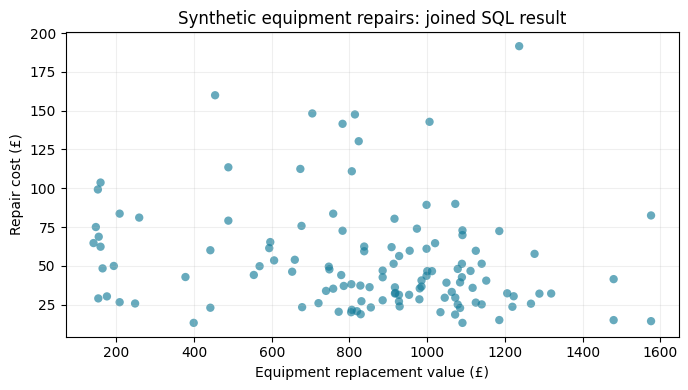

In [7]:
import matplotlib.pyplot as plt
repair_data = pd.read_sql_query('SELECT e.replacement_value_pence/100.0 AS replacement_gbp, r.cost_pence/100.0 AS repair_gbp FROM repairs r JOIN fault_reports f USING(report_id) JOIN equipment e USING(equipment_id);', con)
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(repair_data['replacement_gbp'], repair_data['repair_gbp'], alpha=.65, color='#167d9a', edgecolors='none')
ax.set(xlabel='Equipment replacement value (£)', ylabel='Repair cost (£)', title='Synthetic equipment repairs: joined SQL result')
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


## 8. Saving the files

The database and check results are saved together in a zip file.

All student details are made up. Email addresses use example.invalid to avoid using real contact details. In a real system, access to student information would need to be restricted and old records removed when no longer needed.


In [8]:
con.close()
import zipfile
with zipfile.ZipFile(output_dir / 'database_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
    for filename in [DB_NAME, 'validation_results.json']:
        archive.write(output_dir / filename, arcname=filename)
print('Created:', output_dir / 'database_outputs.zip')


Created: equipment_output/database_outputs.zip
